# CivicAI - 03 Model comparison

This notebook compares two baselines and **six candidate models** that predict `resolved_within_7d` (1 = the request was closed within 7 days, 0 = it took longer), and selects the **three** that will be combined in the stacking classifier of Phase 6.

1. Data and how models are judged
2. Why the cross-validation is time-aware
3. Baselines
4. The selection rule (written before the results)
5. The six candidates and their light tuning (training split only)
6. Validation results for every model
7. ROC curves, confusion matrices and feature importance
8. Selecting three models for the stack

The work was done in two steps. Phase 5 compared Logistic Regression, Random Forest and XGBoost. Phase 5b added Decision Tree, Extra Trees and Bernoulli Naive Bayes to widen the choice. The Phase 5 results and tuned settings are kept exactly as they were.

**Rules followed here**

- Models are tuned with cross-validation on the **training split** and compared on the **validation split**. The **test split is not opened** in this notebook. It is scored once, in Phase 6.
- Every model is the same cleaning step and the same 12 features from `src/features.py`, with an encoder and a classifier on the end. (Naive Bayes needs a different encoder; see section 5.)
- `random_state=42` everywhere, so the numbers can be reproduced.

**Which class matters.** About 83% of requests are class 1 (resolved within 7 days). **Class 0 - not resolved within 7 days - is the one operations staff want to flag**, so its precision, recall and F1 are highlighted in the tables:

- *recall of class 0*: of the requests that really took longer than 7 days, what share did the model flag?
- *precision of class 0*: of the requests the model flagged, what share really took longer than 7 days?

**Main metrics.** Accuracy is misleading here, because always answering "within 7 days" is already right about 83% of the time. The main metrics are **macro F1** (the average of the F1 of class 0 and class 1, so both classes count equally) and **ROC-AUC** (how well the model ranks slow requests above fast ones, whatever cut-off is used).

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve

sys.path.insert(0, "..")                  # so that "src" can be imported from the notebooks folder
from src import features as ft
from src import train as tr

FIG_DIR = Path("../reports/figures")
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7", "#52514e"
YELLOW, MAGENTA, GREEN = "#eda100", "#e87ba4", "#008300"
MODEL_COLORS = {"Logistic Regression": BLUE, "Random Forest": ORANGE, "XGBoost": AQUA,
                "Decision Tree": YELLOW, "Extra Trees": MAGENTA, "Bernoulli Naive Bayes": GREEN}
MODELS = list(MODEL_COLORS)
CORRELATION_LIMIT = 0.97          # part of the selection rule in section 4
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
})

X_train, y_train = tr.load_xy("train", "../data/processed")
X_val, y_val = tr.load_xy("val", "../data/processed")       # test.parquet is not read in this notebook
train_dates = X_train["created_date"]

print(f"Training split  : {len(X_train):,} rows, class 0 share {1 - y_train.mean():.1%}")
print(f"Validation split: {len(X_val):,} rows, class 0 share {1 - y_val.mean():.1%}")
print(f"Final features ({len(ft.FINAL_FEATURES)}): {ft.FINAL_FEATURES}")

Training split  : 139,206 rows, class 0 share 17.2%
Validation split: 29,830 rows, class 0 share 16.8%
Final features (12): ['complaint_type', 'descriptor', 'location_type', 'borough', 'incident_zip', 'open_data_channel_type', 'latitude', 'longitude', 'hour', 'weekday', 'month', 'is_weekend']


## 2. Why the cross-validation is time-aware

**Cross-validation** means: cut the training split into parts, train on some, score on the rest, and repeat, so that a setting is judged on several scores instead of one.

The usual way shuffles the rows at random. That would be wrong here, for the same reason the main split is by time: requests are filed over time, and the model will always be used on requests **newer** than the ones it learned from. With random folds a model would train on December requests and be scored on November ones. It could then pick up things about that period (a cold week, a backlog at one agency) that it could never know in real use, and its scores would look better than they really are.

`TimeSeriesSplit(n_splits=5)` keeps the order. The training split is cut into 6 blocks by date. Fold 1 trains on block 1 and validates on block 2; fold 2 trains on blocks 1-2 and validates on block 3; and so on. **Every fold trains on the past and validates on the next block**, which is what will happen in real use.

Two things to know when reading the results: the early folds train on little data, so their scores are lower and the standard deviation across folds is larger than with random folds; and the first block is never used for validation.

In [2]:
folds = []
for number, (train_index, validate_index) in enumerate(tr.time_folds().split(X_train), 1):
    folds.append({"fold": number,
                  "train_rows": len(train_index),
                  "train_from": train_dates.iloc[train_index[0]].date(), "train_to": train_dates.iloc[train_index[-1]].date(),
                  "validate_rows": len(validate_index),
                  "validate_from": train_dates.iloc[validate_index[0]].date(), "validate_to": train_dates.iloc[validate_index[-1]].date(),
                  "validate_class0_share": 1 - y_train.iloc[validate_index].mean()})
display(pd.DataFrame(folds).style.format({"train_rows": "{:,}", "validate_rows": "{:,}", "validate_class0_share": "{:.1%}"}).hide(axis="index"))

fold,train_rows,train_from,train_to,validate_rows,validate_from,validate_to,validate_class0_share
1,"23,201",2024-01-01,2024-05-08,"23,201",2024-05-08,2024-09-04,19.9%
2,"46,402",2024-01-01,2024-09-04,"23,201",2024-09-04,2024-12-27,16.7%
3,"69,603",2024-01-01,2024-12-27,"23,201",2024-12-27,2025-04-23,15.3%
4,"92,804",2024-01-01,2025-04-23,"23,201",2025-04-23,2025-08-14,17.3%
5,"116,005",2024-01-01,2025-08-14,"23,201",2025-08-14,2025-12-02,14.8%


## 3. Baselines

A model is only useful if it beats a simple rule. Two rules are used:

- **Majority class.** Always answer "resolved within 7 days". It never flags a slow request, so its recall for class 0 is zero.
- **Complaint type only.** For each complaint type, remember from the training split whether most of its requests were resolved within 7 days, and always give that answer. (Its score for ranking is the type's share resolved within 7 days.) A type that is not in the training rows gets the overall majority; in practice rare and new types are already grouped as `Other` by the cleaning step, so they share one answer.

The second baseline is the important one. Notebooks 01 and 02 showed that the complaint type carries most of the signal. This baseline measures exactly how far the complaint type alone gets, so the gap between it and the models is **what the models add** by also using the descriptor, location, channel and time.

In [3]:
baselines = tr.make_baselines()
cv_rows = {}
for name, model in baselines.items():
    cv_rows[name] = tr.cross_validate_model(model, X_train, y_train)
display(pd.DataFrame(cv_rows).T.style.format("{:.4f}"))

,cv_macro_f1_mean,cv_macro_f1_std,cv_roc_auc_mean,cv_roc_auc_std
Baseline: majority class,0.4541,0.0053,0.5000,0.0000
Baseline: complaint type only,0.7989,0.0095,0.9384,0.0095


## 4. The selection rule (written before the results)

Three of the six candidates go into the stack. To keep the choice honest, the rule was fixed **before** the three new candidates were run:

1. **Rank** the six candidates by their mean **cross-validated macro F1 on the training split**. If two are tied, the higher validation macro F1 wins, then the higher validation ROC-AUC.
2. **Take the top 3**, with one exception. A stack only helps if its models make different mistakes, so two models that say almost the same thing are not both useful. If two of the chosen models have a correlation **above 0.97** between their predicted probabilities on the validation split, the lower-ranked one of the pair is dropped and the **next-ranked** candidate takes its place. This is repeated until no chosen pair is above 0.97.
3. If the candidates run out before three can be chosen this way, the remaining places go to the highest-ranked candidates left, and this is stated.

In code this is one pass down the ranking: a candidate is accepted if its correlation with every model already accepted is 0.97 or less.

The test split plays no part in the rule.

## 5. The six candidates and their light tuning

Each model has a few settings that change how it behaves. A small number of settings is tried, each one scored with the 5 time-ordered folds **on the training split only**. The setting with the highest mean **macro F1** across the folds is chosen (ROC-AUC breaks ties).

### Phase 5 models (6 to 8 settings each)

These three were tuned in Phase 5. Their results are **loaded from `reports/tuning_results.csv`, not run again**.

**How each model handles the 17% minority class**

- **Logistic Regression**: `class_weight="balanced"`. A mistake on a class 0 request counts about 5 times as much as a mistake on a class 1 request, so the model cannot ignore the rare class. Setting tried: `C`, the strength of regularisation (smaller `C` = simpler model). `max_iter=3000` so the solver has enough iterations to converge.
- **Random Forest**: `class_weight="balanced_subsample"`, the same idea worked out inside each tree's sample. Settings tried: `max_depth` and `min_samples_leaf`. The number of trees is fixed at 150 and the depth is capped at 40 so the saved file stays small enough for a small server.
- **XGBoost** (`tree_method="hist"`): `scale_pos_weight`. In XGBoost the "positive" class is class 1, our *common* class, so a value **below 1** makes class 1 count less. Two values are tried: the full balance (rows of class 0 / rows of class 1, about 0.21) and a milder half-way value (its square root, about 0.46). Other settings tried: tree depth, and more trees with a smaller learning rate.

### Phase 5b models (4 settings each)

Each list starts with a sensible first setting (`tr.default_settings`) and adds three more. A small pass was needed for all three: the first settings for the two tree models are shallow, and how deep a tree may grow matters a great deal on this data, where the 12 features become several hundred 0/1 columns.

- **Decision Tree**: a single tree, with `class_weight="balanced"`. The depth is limited (`max_depth` 12 to 40) and every leaf must hold at least 20 training requests (`min_samples_leaf`), so the tree cannot memorise single requests.
- **Extra Trees**: like a Random Forest, but each split point is chosen at random, which makes the trees more varied. `class_weight="balanced_subsample"`; Extra Trees does not resample the rows, so this gives the same weights as `"balanced"`. It is kept to 100 trees with a depth limit so the saved file stays small enough for a small server.
- **Bernoulli Naive Bayes**: a very simple model that treats every input as a yes/no fact and assumes the facts are independent.
  - *Features that suit it.* It is not given the scaled numbers the other models use. It gets its own encoder, `ft.build_binary_encoder`, in which **every column is 0 or 1**: the text columns as before, one column per hour, weekday and month, and latitude and longitude each cut into 10 bands with equal numbers of training requests (missing coordinates are first filled with the training median). The cleaning step and the 12 features are the same as for every other model.
  - *The minority class.* It has **no class weights**. What it does have is `class_prior`: how common it should assume each class is. Two options are tried: `[0.5, 0.5]` (treat both classes as equally common, the nearest thing to "balanced" weights) and `None` (use the real shares, about 17% and 83%). Cross-validation on the training split chooses between them, together with the smoothing setting `alpha`.

In [4]:
settings = tr.settings_to_try(y_train)
print(f"scale_pos_weight values tried for XGBoost: full balance = {tr.class_ratio(y_train):.4f}, half-way = {np.sqrt(tr.class_ratio(y_train)):.4f}")

best_settings = {}
for name in tr.PHASE5_MODELS + tr.PHASE5B_MODELS:
    settings_list = settings[name]
    start = time.time()
    table, was_loaded = tr.load_or_tune(name, settings_list, X_train, y_train, "../reports/tuning_results.csv")
    best_settings[name] = json.loads(table.loc[0, "settings"])
    cv_rows[name] = table.loc[0, ["cv_macro_f1_mean", "cv_macro_f1_std", "cv_roc_auc_mean", "cv_roc_auc_std"]].astype(float).to_dict()
    how = "loaded from reports/tuning_results.csv, not run again" if was_loaded else f"tuned now in {time.time() - start:.0f} s"
    print(f"\n{name}: {len(settings_list)} settings x 5 folds, {how}. Best first:")
    with pd.option_context("display.max_colwidth", None):
        display(table.drop(columns="model").style.format({c: "{:.4f}" for c in table.columns if c.startswith("cv_") and c != "cv_seconds"})
                .format({"cv_seconds": "{:.0f}"}).set_properties(subset=["settings"], **{"text-align": "left"}))

Path("../reports/best_settings.json").write_text(json.dumps(best_settings, indent=2), encoding="utf-8")
print("\nBest settings:")
for name, chosen in best_settings.items():
    print(f"  {name}: {chosen}")
print("reports/tuning_results.csv holds every setting tried; reports/best_settings.json holds the best one per model.")

scale_pos_weight values tried for XGBoost: full balance = 0.2076, half-way = 0.4556

Logistic Regression: 6 settings x 5 folds, loaded from reports/tuning_results.csv, not run again. Best first:


,settings,cv_macro_f1_mean,cv_macro_f1_std,cv_roc_auc_mean,cv_roc_auc_std,cv_seconds
0,"{""C"": 0.3}",0.802406,0.008454,0.943968,0.009074,20
1,"{""C"": 3.0}",0.802348,0.008157,0.944222,0.008733,59
2,"{""C"": 1.0}",0.802161,0.008277,0.944238,0.008794,36
3,"{""C"": 0.1}",0.800624,0.008059,0.943172,0.009629,33
4,"{""C"": 0.03}",0.796684,0.007764,0.940409,0.011108,33
5,"{""C"": 0.01}",0.783032,0.011962,0.934865,0.013296,31



Random Forest: 6 settings x 5 folds, loaded from reports/tuning_results.csv, not run again. Best first:


,settings,cv_macro_f1_mean,cv_macro_f1_std,cv_roc_auc_mean,cv_roc_auc_std,cv_seconds
0,"{""n_estimators"": 150, ""max_depth"": 40, ""min_samples_leaf"": 5}",0.794336,0.007697,0.942600,0.008759,59
1,"{""n_estimators"": 150, ""max_depth"": 40, ""min_samples_leaf"": 10}",0.786489,0.007591,0.940587,0.009634,68
2,"{""n_estimators"": 150, ""max_depth"": 40, ""min_samples_leaf"": 20}",0.775471,0.007631,0.938049,0.010427,53
3,"{""n_estimators"": 150, ""max_depth"": 30, ""min_samples_leaf"": 5}",0.775087,0.005950,0.940442,0.008537,67
4,"{""n_estimators"": 150, ""max_depth"": 30, ""min_samples_leaf"": 10}",0.771340,0.006224,0.938609,0.008961,53
5,"{""n_estimators"": 150, ""max_depth"": 20, ""min_samples_leaf"": 5}",0.744840,0.009548,0.935771,0.008825,75



XGBoost: 8 settings x 5 folds, loaded from reports/tuning_results.csv, not run again. Best first:


,settings,cv_macro_f1_mean,cv_macro_f1_std,cv_roc_auc_mean,cv_roc_auc_std,cv_seconds
0,"{""n_estimators"": 600, ""learning_rate"": 0.05, ""max_depth"": 8, ""scale_pos_weight"": 0.4556}",0.823166,0.012726,0.945828,0.009336,69
1,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 8, ""scale_pos_weight"": 0.4556}",0.822917,0.012979,0.945815,0.009420,31
2,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 6, ""scale_pos_weight"": 0.4556}",0.822614,0.011480,0.945689,0.008999,31
3,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 4, ""scale_pos_weight"": 0.4556}",0.821044,0.011987,0.944669,0.008400,49
4,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 8, ""scale_pos_weight"": 0.2076}",0.803154,0.012003,0.945873,0.009367,48
5,"{""n_estimators"": 600, ""learning_rate"": 0.05, ""max_depth"": 8, ""scale_pos_weight"": 0.2076}",0.802918,0.011624,0.945813,0.009321,67
6,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 6, ""scale_pos_weight"": 0.2076}",0.799833,0.011453,0.945662,0.009234,38
7,"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 4, ""scale_pos_weight"": 0.2076}",0.786932,0.010348,0.944206,0.008573,40


... (3 outputs left out)

,settings,cv_macro_f1_mean,cv_macro_f1_std,cv_roc_auc_mean,cv_roc_auc_std,cv_seconds
0,"{""n_estimators"": 100, ""max_depth"": 40, ""min_samples_leaf"": 5}",0.793738,0.008458,0.943556,0.008164,39
1,"{""n_estimators"": 100, ""max_depth"": 40, ""min_samples_leaf"": 10}",0.788603,0.008072,0.942042,0.008563,33
2,"{""n_estimators"": 100, ""max_depth"": 30, ""min_samples_leaf"": 5}",0.776966,0.007303,0.941189,0.008172,35
3,"{""n_estimators"": 100, ""max_depth"": 20, ""min_samples_leaf"": 5}",0.743567,0.008316,0.935891,0.008425,31



Bernoulli Naive Bayes: 4 settings x 5 folds, loaded from reports/tuning_results.csv, not run again. Best first:


,settings,cv_macro_f1_mean,cv_macro_f1_std,cv_roc_auc_mean,cv_roc_auc_std,cv_seconds
0,"{""alpha"": 0.1, ""class_prior"": null}",0.799687,0.009578,0.936832,0.009420,16
1,"{""alpha"": 1.0, ""class_prior"": null}",0.799236,0.009552,0.936493,0.009506,16
2,"{""alpha"": 0.1, ""class_prior"": [0.5, 0.5]}",0.774146,0.007804,0.936832,0.009420,16
3,"{""alpha"": 1.0, ""class_prior"": [0.5, 0.5]}",0.772217,0.007568,0.936493,0.009506,17



Best settings:
  Logistic Regression: {'C': 0.3}
  Random Forest: {'n_estimators': 150, 'max_depth': 40, 'min_samples_leaf': 5}
  XGBoost: {'n_estimators': 600, 'learning_rate': 0.05, 'max_depth': 8, 'scale_pos_weight': 0.4556}
  Decision Tree: {'max_depth': 40, 'min_samples_leaf': 20}
  Extra Trees: {'n_estimators': 100, 'max_depth': 40, 'min_samples_leaf': 5}
  Bernoulli Naive Bayes: {'alpha': 0.1, 'class_prior': None}
reports/tuning_results.csv holds every setting tried; reports/best_settings.json holds the best one per model.


**Cross-validation summary** (training split, 5 time-ordered folds): the two baselines and each candidate at its best setting, best first. This is the ranking used by the selection rule.

In [5]:
cv_summary = pd.DataFrame(cv_rows).T
cv_summary["macro F1 (mean +/- std)"] = [f"{m:.4f} +/- {s:.4f}" for m, s in zip(cv_summary["cv_macro_f1_mean"], cv_summary["cv_macro_f1_std"])]
cv_summary["ROC-AUC (mean +/- std)"] = [f"{m:.4f} +/- {s:.4f}" for m, s in zip(cv_summary["cv_roc_auc_mean"], cv_summary["cv_roc_auc_std"])]
display(cv_summary.sort_values("cv_macro_f1_mean", ascending=False)[["macro F1 (mean +/- std)", "ROC-AUC (mean +/- std)"]])

,macro F1 (mean +/- std),ROC-AUC (mean +/- std)
XGBoost,0.8232 +/- 0.0127,0.9458 +/- 0.0093
Logistic Regression,0.8024 +/- 0.0085,0.9440 +/- 0.0091
Bernoulli Naive Bayes,0.7997 +/- 0.0096,0.9368 +/- 0.0094
Baseline: complaint type only,0.7989 +/- 0.0095,0.9384 +/- 0.0095
Random Forest,0.7943 +/- 0.0077,0.9426 +/- 0.0088
Extra Trees,0.7937 +/- 0.0085,0.9436 +/- 0.0082
Decision Tree,0.7885 +/- 0.0089,0.9197 +/- 0.0084
Baseline: majority class,0.4541 +/- 0.0053,0.5000 +/- 0.0000


## 6. Validation results

Each tuned model is now fitted once on the **full training split** and scored on the **validation split**, which none of the tuning above has seen. The same is done for the two baselines.

Also recorded, because the model has to run on a small EC2 server:

- **training time** on this laptop,
- **saved file size** with `joblib` (the whole pipeline, cleaning and encoding included),
- **time to predict one request** (the median of 20 calls, starting from the raw request fields).

In [6]:
one_request = X_val.iloc[[0]]
fitted, probabilities, rows = {}, {}, []

candidates = dict(baselines)
candidates.update({name: tr.make_model(name, best_settings[name]) for name in MODELS})
for name, model in candidates.items():
    train_seconds = tr.fit_timed(model, X_train, y_train)
    metrics, probabilities[name] = tr.evaluate(model, X_val, y_val)
    fitted[name] = model
    rows.append({"model": name, **metrics, **cv_rows[name],
                 "train_seconds": train_seconds, "file_mb": tr.saved_size_mb(model),
                 "predict_one_ms": tr.predict_one_ms(model, one_request),
                 "settings": json.dumps(best_settings.get(name, {}))})

comparison = pd.DataFrame(rows).set_index("model")     # saved in section 8, once the selection is known

iterations = fitted["Logistic Regression"]["model"].n_iter_[0]
print(f"Logistic Regression converged in {iterations} iterations (limit 3000).")

Logistic Regression converged in 105 iterations (limit 3000).


In [7]:
CLASS0 = ["precision_0", "recall_0", "f1_0"]
main_columns = ["accuracy"] + CLASS0 + ["precision_1", "recall_1", "f1_1", "macro_f1", "roc_auc"]
print("Validation split. Class 0 (not resolved within 7 days) is highlighted.")
display(comparison[main_columns].style.format("{:.4f}")
        .set_properties(subset=CLASS0, **{"background-color": "#fdebd8", "color": "black", "font-weight": "bold"})
        .highlight_max(subset=["macro_f1", "roc_auc"], props="text-decoration: underline; font-weight: bold"))

print("Confusion matrix counts (validation split)")
display(comparison[["actual0_pred0", "actual0_pred1", "actual1_pred0", "actual1_pred1"]]
        .rename(columns={"actual0_pred0": "slow, flagged (correct)", "actual0_pred1": "slow, missed",
                         "actual1_pred0": "fast, flagged by mistake", "actual1_pred1": "fast, not flagged (correct)"})
        .style.format("{:,}"))

print("Cost of each model")
display(comparison[["train_seconds", "file_mb", "predict_one_ms"]].style.format({"train_seconds": "{:.1f}", "file_mb": "{:.2f}", "predict_one_ms": "{:.1f}"}))

Validation split. Class 0 (not resolved within 7 days) is highlighted.


,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1,roc_auc
model,,,,,,,,,
Baseline: majority class,0.8321,0.0000,0.0000,0.0000,0.8321,1.0000,0.9084,0.4542,0.5000
Baseline: complaint type only,0.8915,0.6866,0.6499,0.6678,0.9301,0.9402,0.9351,0.8014,0.9377
Logistic Regression,0.8791,0.5963,0.8658,0.7062,0.9702,0.8818,0.9239,0.8150,0.9414
Random Forest,0.8542,0.5398,0.8906,0.6721,0.9746,0.8468,0.9062,0.7892,0.9408
XGBoost,0.8994,0.6620,0.8189,0.7321,0.9616,0.9157,0.9381,0.8351,0.9433
Decision Tree,0.8733,0.5802,0.8876,0.7017,0.9746,0.8705,0.9196,0.8107,0.9113
Extra Trees,0.8546,0.5400,0.9039,0.6761,0.9776,0.8447,0.9063,0.7912,0.9418
Bernoulli Naive Bayes,0.8762,0.5918,0.8460,0.6964,0.9660,0.8823,0.9222,0.8093,0.9377


Confusion matrix counts (validation split)


,"slow, flagged (correct)","slow, missed","fast, flagged by mistake","fast, not flagged (correct)"
model,,,,
Baseline: majority class,0,"5,007",0,"24,823"
Baseline: complaint type only,"3,254","1,753","1,485","23,338"
Logistic Regression,"4,335",672,"2,935","21,888"
Random Forest,"4,459",548,"3,802","21,021"
XGBoost,"4,100",907,"2,093","22,730"
Decision Tree,"4,444",563,"3,215","21,608"
Extra Trees,"4,526",481,"3,856","20,967"
Bernoulli Naive Bayes,"4,236",771,"2,922","21,901"


Cost of each model


,train_seconds,file_mb,predict_one_ms
model,,,
Baseline: majority class,0.0,0.00,0.0
Baseline: complaint type only,4.8,0.02,23.1
Logistic Regression,6.2,0.03,28.9
Random Forest,23.3,17.98,60.9
XGBoost,9.5,1.81,47.5
Decision Tree,9.7,0.26,27.5
Extra Trees,18.1,15.20,60.1
Bernoulli Naive Bayes,5.0,0.05,29.6


**Reading the results (validation split, 29,830 requests of which 5,007 are class 0).**

- **The complaint-type baseline is strong.** Knowing only the complaint type already gives macro F1 0.801 and ROC-AUC 0.938. This confirms what notebooks 01 and 02 showed: most of the signal is in what the request is about.
- **XGBoost is the best model** on macro F1 (0.835), ROC-AUC (0.943) and accuracy (0.899). Compared with the complaint-type baseline it adds 0.034 macro F1, and it flags 82% of slow requests instead of 65%.
- **Logistic Regression** (0.815), **Decision Tree** (0.811) and **Bernoulli Naive Bayes** (0.809) form a second group, a little above the baseline on macro F1. The Decision Tree ranks requests clearly worse than the others (ROC-AUC 0.911, below the baseline), because a single tree gives only a coarse set of probabilities.
- **Random Forest** (0.789) and **Extra Trees** (0.791) flag the most slow requests (89% and 90%) but with the most false alarms: only 54% of their flags are right. Their macro F1 is slightly **below** the complaint-type baseline, although they rank requests better than it does (ROC-AUC 0.941 and 0.942). For both, the best setting was the deepest one allowed.
- **The class weights explain the pattern.** The weighted models are told to care more about the rare class 0, so they flag far more slow requests than the baseline and pay for it with more false alarms. XGBoost did best with the milder weighting (0.46), which is why it has the fewest false alarms of the weighted models.
- **Naive Bayes and the minority class.** Cross-validation preferred the real class shares (`class_prior=None`, macro F1 0.800) over equal shares (`[0.5, 0.5]`, 0.774). Even without any balancing it flags 85% of slow requests. Naive Bayes counts every feature as separate evidence, so its probabilities are pushed towards 0 or 1 and it already flags readily; treating the classes as equally common pushed it too far and added false alarms.
- **Cross-validation and validation mostly agree.** XGBoost is first in both. The only real disagreement is the Decision Tree, which is last in cross-validation (0.789) but third on the validation split (0.811).
- **Cost is not a constraint.** Every model trains in under a minute, the largest saved file is 18 MB (Random Forest; Extra Trees is 15 MB), and one prediction takes well under 0.1 seconds on this laptop.

## 7. Charts

### ROC curves

For every possible cut-off, the ROC curve shows the share of fast requests correctly recognised (y axis) against the share of slow requests wrongly called fast (x axis). A curve closer to the top-left corner is better; the diagonal is a model that guesses. The area under the curve is the ROC-AUC.

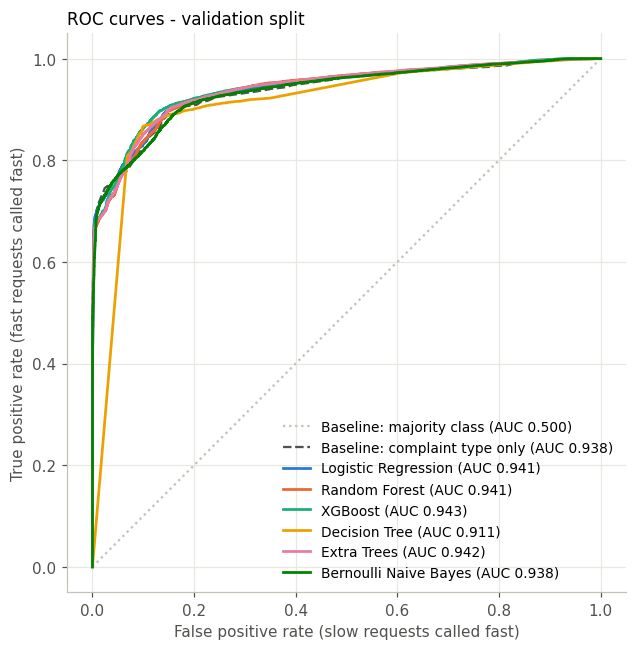

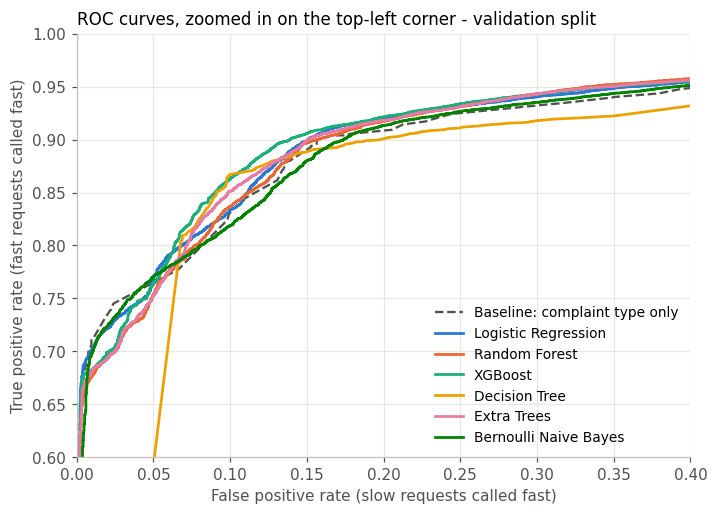

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 6.6))
ax.plot([0, 1], [0, 1], color=GREY, linewidth=1.5, linestyle=":",
        label=f"Baseline: majority class (AUC {comparison.loc['Baseline: majority class', 'roc_auc']:.3f})")
fpr, tpr, _ = roc_curve(y_val, probabilities["Baseline: complaint type only"])
ax.plot(fpr, tpr, color=INK, linewidth=1.5, linestyle="--",
        label=f"Baseline: complaint type only (AUC {comparison.loc['Baseline: complaint type only', 'roc_auc']:.3f})")
for name, color in MODEL_COLORS.items():
    fpr, tpr, _ = roc_curve(y_val, probabilities[name])
    ax.plot(fpr, tpr, color=color, linewidth=1.8, label=f"{name} (AUC {comparison.loc[name, 'roc_auc']:.3f})")
ax.set_xlabel("False positive rate (slow requests called fast)")
ax.set_ylabel("True positive rate (fast requests called fast)")
ax.set_title("ROC curves - validation split", loc="left", fontsize=11)
ax.set_aspect("equal")
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.savefig(FIG_DIR / "05_roc_curves.png")
plt.show()

# The curves lie close together, so the same plot again, zoomed in on the top-left corner
fig, ax = plt.subplots(figsize=(7.2, 5))
fpr, tpr, _ = roc_curve(y_val, probabilities["Baseline: complaint type only"])
ax.plot(fpr, tpr, color=INK, linewidth=1.5, linestyle="--", label="Baseline: complaint type only")
for name, color in MODEL_COLORS.items():
    fpr, tpr, _ = roc_curve(y_val, probabilities[name])
    ax.plot(fpr, tpr, color=color, linewidth=1.8, label=name)
ax.set_xlim(0, 0.4)
ax.set_ylim(0.6, 1.0)
ax.set_xlabel("False positive rate (slow requests called fast)")
ax.set_ylabel("True positive rate (fast requests called fast)")
ax.set_title("ROC curves, zoomed in on the top-left corner - validation split", loc="left", fontsize=11)
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.savefig(FIG_DIR / "05_roc_curves_zoom.png")
plt.show()

### Confusion matrices

Each matrix counts the validation requests by what really happened (rows) and what the model predicted (columns). The percentages are shares of each row, so the top-left cell is the **recall of class 0**: the share of slow requests the model flagged.

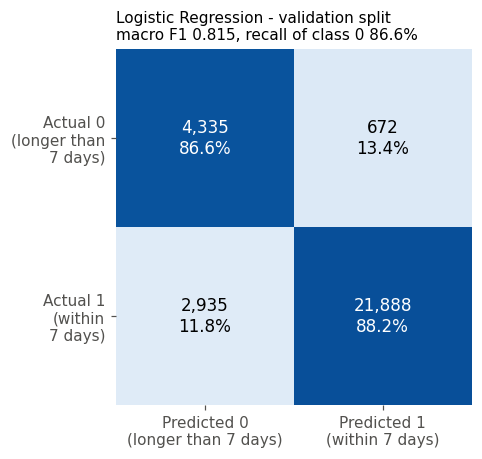

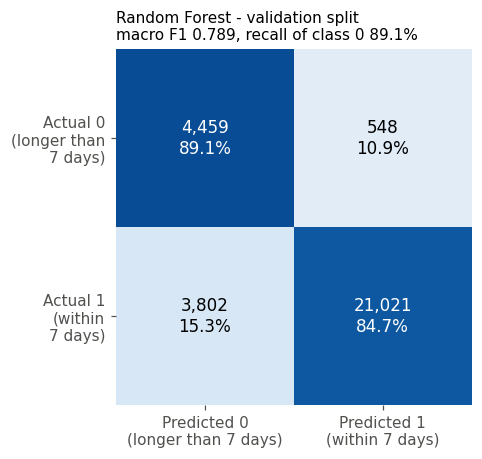

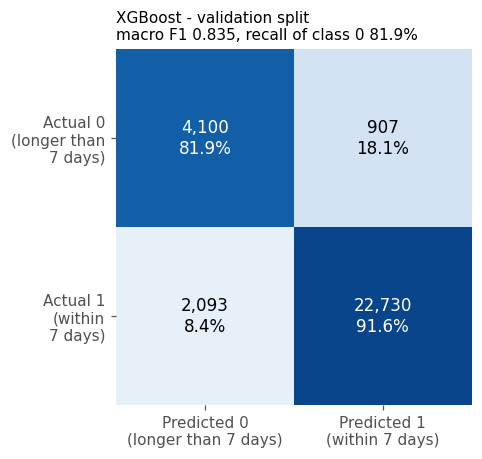

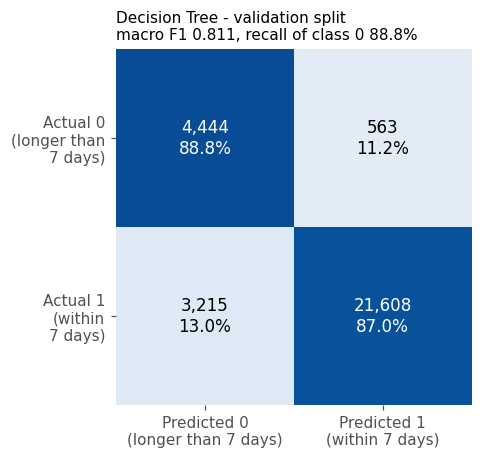

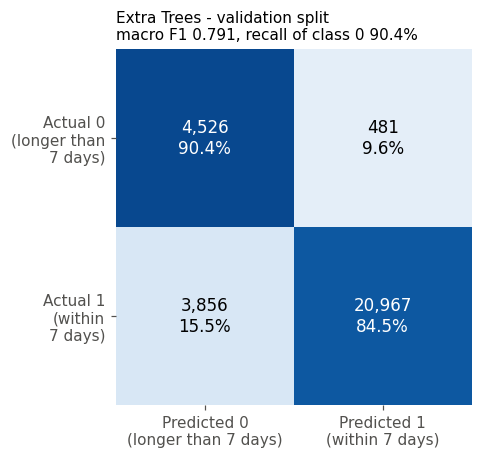

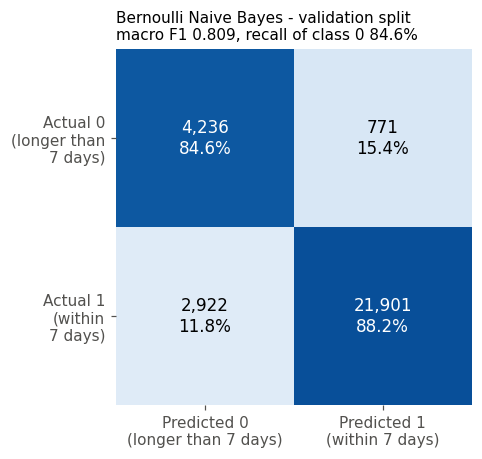

In [9]:
def plot_confusion(name, filename):
    row = comparison.loc[name]
    counts = np.array([[row["actual0_pred0"], row["actual0_pred1"]], [row["actual1_pred0"], row["actual1_pred1"]]], dtype=float)
    shares = counts / counts.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(counts[i, j]):,}\n{shares[i, j]:.1%}", ha="center", va="center", fontsize=11,
                    color="white" if shares[i, j] > 0.55 else "black")
    ax.set_xticks([0, 1], ["Predicted 0\n(longer than 7 days)", "Predicted 1\n(within 7 days)"])
    ax.set_yticks([0, 1], ["Actual 0\n(longer than\n7 days)", "Actual 1\n(within\n7 days)"])
    ax.set_title(f"{name} - validation split\nmacro F1 {row['macro_f1']:.3f}, recall of class 0 {row['recall_0']:.1%}",
                 loc="left", fontsize=10)
    ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)
    fig.savefig(FIG_DIR / filename)
    plt.show()

plot_confusion("Logistic Regression", "05_confusion_logistic_regression.png")
plot_confusion("Random Forest", "05_confusion_random_forest.png")
plot_confusion("XGBoost", "05_confusion_xgboost.png")
plot_confusion("Decision Tree", "05_confusion_decision_tree.png")
plot_confusion("Extra Trees", "05_confusion_extra_trees.png")
plot_confusion("Bernoulli Naive Bayes", "05_confusion_bernoulli_naive_bayes.png")

### Feature importance of the best tree model

The tree model with the highest validation macro F1 is used (out of Decision Tree, Random Forest, Extra Trees and XGBoost). Its importance is reported per encoded column (one per category), so the columns are **added back up to the original 12 features**. For XGBoost the measure is the gain of its splits; for the others it is the average reduction in impurity. Both come from the training data and tend to favour features with many categories, so read this as "what the model used", not as proof of what matters.

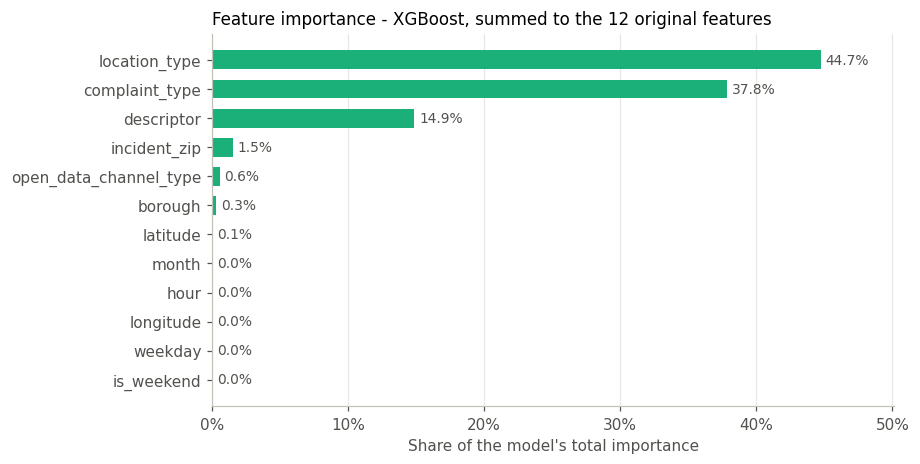

Best tree model by validation macro F1: XGBoost


,importance_share
location_type,44.7%
complaint_type,37.8%
descriptor,14.9%
incident_zip,1.5%
open_data_channel_type,0.6%
borough,0.3%
latitude,0.1%
month,0.0%
hour,0.0%
longitude,0.0%


In [10]:
best_tree = comparison.loc[["Decision Tree", "Random Forest", "Extra Trees", "XGBoost"], "macro_f1"].idxmax()
importance = tr.importance_by_feature(fitted[best_tree])
importance = importance / importance.sum()
assert set(importance.index) == set(ft.FINAL_FEATURES)

plot = importance.sort_values()
fig, ax = plt.subplots(figsize=(8, 4.4))
bars = ax.barh(plot.index, plot.values, color=MODEL_COLORS[best_tree], height=0.65)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in plot.values], color=INK, fontsize=9, padding=3)
ax.set_xlim(0, plot.max() * 1.12)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Share of the model's total importance")
ax.set_title(f"Feature importance - {best_tree}, summed to the 12 original features", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "05_feature_importance_best_tree.png")
plt.show()
print(f"Best tree model by validation macro F1: {best_tree}")
display(importance.rename("importance_share").to_frame().style.format("{:.1%}"))

## 8. Selecting three models for the stack

The rule from section 4 is now applied. It needs, for the six candidates:

- the **ranking** by cross-validated macro F1 (training split), with the validation scores as tie-breaks;
- the **correlation** between the models' predicted probabilities on the validation split (1.00 = two models say the same thing);
- for information, the **disagreement**: how often two models give a different yes/no answer for the same request.

In [11]:
ranked = comparison.loc[MODELS].sort_values(["cv_macro_f1_mean", "macro_f1", "roc_auc"], ascending=False)
ranking = ranked[["cv_macro_f1_mean", "cv_macro_f1_std", "macro_f1", "roc_auc"]].copy()
ranking.insert(0, "rank", range(1, len(ranking) + 1))
print("Ranking of the six candidates (rule step 1)")
display(ranking.style.format({c: "{:.4f}" for c in ranking.columns if c != "rank"}))

proba = pd.DataFrame({name: probabilities[name] for name in ranked.index})
predicted = (proba >= 0.5).astype(int)
correlation = proba.corr()
print("Correlation of predicted probabilities, validation split (above 0.97 is highlighted)")
display(correlation.style.format("{:.3f}").map(
    lambda v: "background-color: #fdebd8; color: black; font-weight: bold" if CORRELATION_LIMIT < v < 0.9999 else ""))

disagreement = pd.DataFrame({a: {b: (predicted[a] != predicted[b]).mean() for b in proba.columns} for a in proba.columns})
print("Share of validation requests where two models give a different answer")
display(disagreement.style.format("{:.1%}"))

Ranking of the six candidates (rule step 1)


,rank,cv_macro_f1_mean,cv_macro_f1_std,macro_f1,roc_auc
model,,,,,
XGBoost,1,0.8232,0.0127,0.8351,0.9433
Logistic Regression,2,0.8024,0.0085,0.8150,0.9414
Bernoulli Naive Bayes,3,0.7997,0.0096,0.8093,0.9377
Random Forest,4,0.7943,0.0077,0.7892,0.9408
Extra Trees,5,0.7937,0.0085,0.7912,0.9418
Decision Tree,6,0.7885,0.0089,0.8107,0.9113


Correlation of predicted probabilities, validation split (above 0.97 is highlighted)


,XGBoost,Logistic Regression,Bernoulli Naive Bayes,Random Forest,Extra Trees,Decision Tree
XGBoost,1.000,0.975,0.951,0.951,0.954,0.941
Logistic Regression,0.975,1.000,0.954,0.975,0.977,0.923
Bernoulli Naive Bayes,0.951,0.954,1.000,0.925,0.923,0.901
Random Forest,0.951,0.975,0.925,1.000,0.998,0.904
Extra Trees,0.954,0.977,0.923,0.998,1.000,0.907
Decision Tree,0.941,0.923,0.901,0.904,0.907,1.000


Share of validation requests where two models give a different answer


,XGBoost,Logistic Regression,Bernoulli Naive Bayes,Random Forest,Extra Trees,Decision Tree
XGBoost,0.0%,4.0%,4.1%,7.0%,7.4%,5.3%
Logistic Regression,4.0%,0.0%,3.9%,5.1%,5.2%,4.5%
Bernoulli Naive Bayes,4.1%,3.9%,0.0%,5.3%,6.2%,5.6%
Random Forest,7.0%,5.1%,5.3%,0.0%,2.7%,5.9%
Extra Trees,7.4%,5.2%,6.2%,2.7%,0.0%,5.7%
Decision Tree,5.3%,4.5%,5.6%,5.9%,5.7%,0.0%


In [12]:
# Rule step 2: one pass down the ranking
selected, notes = [], []
for name in ranked.index:
    if len(selected) == 3:
        break
    too_close = [chosen for chosen in selected if correlation.loc[name, chosen] > CORRELATION_LIMIT]
    if too_close:
        notes.append(f"rank {ranking.loc[name, 'rank']}  {name}: SKIPPED, correlation "
                     + ", ".join(f"{correlation.loc[name, c]:.3f} with {c}" for c in too_close))
    else:
        selected.append(name)
        notes.append(f"rank {ranking.loc[name, 'rank']}  {name}: SELECTED")
# Rule step 3: only used if fewer than three passed
for name in ranked.index:
    if len(selected) < 3 and name not in selected:
        selected.append(name)
        notes.append(f"rank {ranking.loc[name, 'rank']}  {name}: SELECTED to fill the last place (rule step 3)")

print("\n".join(notes))
top3 = list(ranked.index[:3])
print(f"\nTop 3 by rank alone : {top3}")
print(f"Selected for stack  : {selected}")
print("The correlation rule changed the pick." if set(top3) != set(selected) else "The correlation rule did not change the pick.")

print("\nCorrelation between the selected three")
display(correlation.loc[selected, selected].style.format("{:.3f}"))

comparison["selected_for_stack"] = comparison.index.isin(selected)
comparison.to_csv("../reports/model_comparison.csv")
print("Saved ../reports/model_comparison.csv (one row per model and baseline, with selected_for_stack)")

rank 1  XGBoost: SELECTED
rank 2  Logistic Regression: SKIPPED, correlation 0.975 with XGBoost
rank 3  Bernoulli Naive Bayes: SELECTED
rank 4  Random Forest: SELECTED

Top 3 by rank alone : ['XGBoost', 'Logistic Regression', 'Bernoulli Naive Bayes']
Selected for stack  : ['XGBoost', 'Bernoulli Naive Bayes', 'Random Forest']
The correlation rule changed the pick.

Correlation between the selected three


,XGBoost,Bernoulli Naive Bayes,Random Forest
XGBoost,1.000,0.951,0.951
Bernoulli Naive Bayes,0.951,1.000,0.925
Random Forest,0.951,0.925,1.000


Saved ../reports/model_comparison.csv (one row per model and baseline, with selected_for_stack)


**How much can the selected three gain together?** For each validation request, either all three are right, all three are wrong, or they disagree. A stack can only improve on the requests where they disagree. "At least one model right" is an upper limit that no real stack reaches, because the stack does not know which model to believe.

In [13]:
from sklearn.metrics import f1_score, roc_auc_score

best_model = comparison.loc[MODELS].sort_values(["macro_f1", "roc_auc"], ascending=False).index[0]
correct = predicted.eq(y_val.to_numpy(), axis=0)

def diversity(names):
    c = correct[list(names)]
    average = proba[list(names)].mean(axis=1)
    return {"all three right": c.all(axis=1).mean(), "all three wrong": (~c).all(axis=1).mean(),
            "they disagree": (c.any(axis=1) & ~c.all(axis=1)).mean(), "at least one right": c.any(axis=1).mean(),
            "highest correlation in the trio": correlation.loc[list(names), list(names)].where(lambda t: t < 0.9999).max().max(),
            "simple average: macro F1": f1_score(y_val, average >= 0.5, average="macro"),
            "simple average: ROC-AUC": roc_auc_score(y_val, average)}

trios = {"Selected: " + ", ".join(selected): diversity(selected)}
if set(top3) != set(selected):
    trios["Top 3 by rank: " + ", ".join(top3)] = diversity(top3)
if set(tr.PHASE5_MODELS) not in (set(selected), set(top3)):
    trios["Phase 5 trio: " + ", ".join(tr.PHASE5_MODELS)] = diversity(tr.PHASE5_MODELS)
display(pd.DataFrame(trios).T.style.format("{:.1%}").format("{:.3f}", subset=["highest correlation in the trio"])
        .format("{:.4f}", subset=["simple average: macro F1", "simple average: ROC-AUC"]))

print(f"Best single model on validation: {best_model} - right for {correct[best_model].mean():.1%} of requests, "
      f"macro F1 {comparison.loc[best_model, 'macro_f1']:.4f}, ROC-AUC {comparison.loc[best_model, 'roc_auc']:.4f}")
print(f"At least one of the selected three is right for {correct[selected].any(axis=1).mean():.1%} of requests "
      f"({correct[selected].any(axis=1).mean() - correct[best_model].mean():+.1%} against the best single model).")

,all three right,all three wrong,they disagree,at least one right,highest correlation in the trio,simple average: macro F1,simple average: ROC-AUC
"Selected: XGBoost, Bernoulli Naive Bayes, Random Forest",83.2%,8.6%,8.2%,91.4%,0.951,0.8252,0.9420
"Top 3 by rank: XGBoost, Logistic Regression, Bernoulli Naive Bayes",85.2%,8.8%,6.0%,91.2%,0.975,0.8272,0.9425
"Phase 5 trio: Logistic Regression, Random Forest, XGBoost",83.4%,8.6%,8.1%,91.4%,0.975,0.8296,0.9433


Best single model on validation: XGBoost - right for 89.9% of requests, macro F1 0.8351, ROC-AUC 0.9433
At least one of the selected three is right for 91.4% of requests (+1.5% against the best single model).


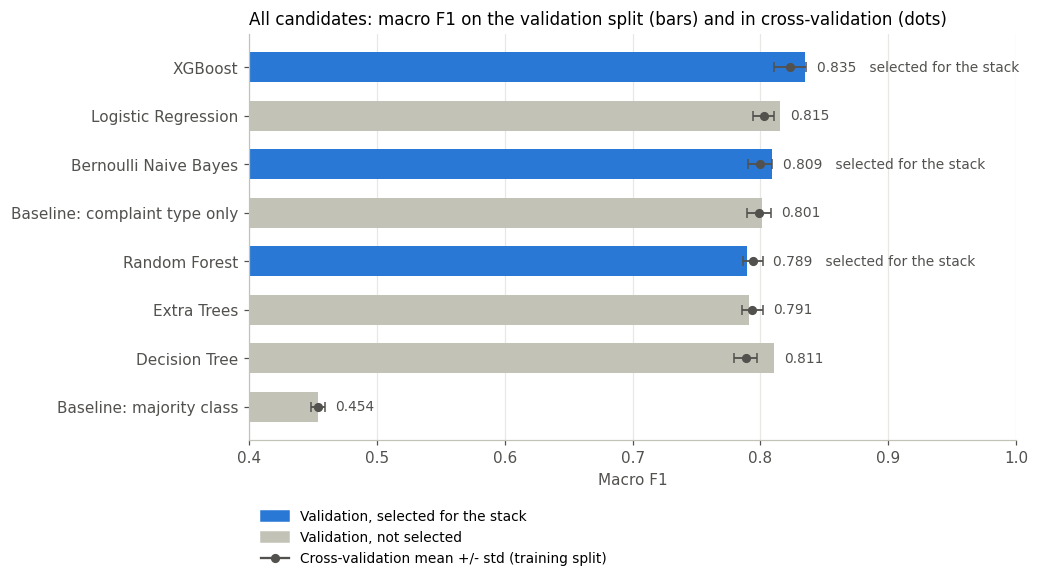

In [14]:
order = comparison.sort_values("cv_macro_f1_mean").index            # best at the top of the chart
fig, ax = plt.subplots(figsize=(9, 4.8))
positions = np.arange(len(order))
ax.barh(positions, comparison.loc[order, "macro_f1"], height=0.62,
        color=[BLUE if comparison.loc[name, "selected_for_stack"] else GREY for name in order])
ax.errorbar(comparison.loc[order, "cv_macro_f1_mean"], positions, xerr=comparison.loc[order, "cv_macro_f1_std"],
            fmt="o", color=INK, markersize=5, capsize=3, linewidth=1.2)
for position, name in zip(positions, order):
    tag = "   selected for the stack" if comparison.loc[name, "selected_for_stack"] else ""
    ax.text(max(comparison.loc[name, "macro_f1"], comparison.loc[name, "cv_macro_f1_mean"] + comparison.loc[name, "cv_macro_f1_std"]) + 0.008,
            position, f"{comparison.loc[name, 'macro_f1']:.3f}{tag}", va="center", color=INK, fontsize=9)
ax.set_yticks(positions, order)
ax.set_xlim(0.4, 1.0)
ax.set_xlabel("Macro F1")
ax.set_title("All candidates: macro F1 on the validation split (bars) and in cross-validation (dots)", loc="left", fontsize=11)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="Validation, selected for the stack"), Patch(color=GREY, label="Validation, not selected"),
                   Line2D([], [], color=INK, marker="o", linestyle="-", markersize=5, label="Cross-validation mean +/- std (training split)")],
          loc="upper left", bbox_to_anchor=(0, -0.14), frameon=False, fontsize=9)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "05_model_comparison_selected.png")
plt.show()

**Selected for the stack: XGBoost, Bernoulli Naive Bayes and Random Forest.**

**How the rule produced this.**

1. By cross-validated macro F1 the top three were XGBoost (0.823), Logistic Regression (0.802) and Bernoulli Naive Bayes (0.800).
2. XGBoost and Logistic Regression have a correlation of **0.975**, above the 0.97 limit, so Logistic Regression (the lower-ranked of the pair) was dropped.
3. Naive Bayes was accepted: its correlation with XGBoost is 0.951.
4. The next-ranked model, Random Forest, was accepted: 0.951 with XGBoost and 0.925 with Naive Bayes.

**So the correlation rule changed the pick**: Random Forest replaced Logistic Regression. The three selected models are also three different kinds of model (boosted trees, a probability model, and averaged trees), and no pair is above 0.951.

**What the rule cost.** Logistic Regression has the second-best scores of all six candidates and it is not in the stack. Random Forest, which takes its place, is weaker on its own (validation macro F1 0.789 against 0.815). The rule deliberately trades individual strength for variety.

**Does the variety pay off? On this evidence, only a little.**

- At least one of the selected three is right for 91.4% of validation requests, against 89.9% for XGBoost alone. That 1.5-point gap is the most any combination could gain, and a real stack reaches only part of it.
- All three are wrong on the same 8.6% of requests, which no combination can fix.
- The top three by rank alone would have had less room (91.2%), and the Phase 5 trio the same room (91.4%).
- A simple average of the selected three scores macro F1 0.825 and ROC-AUC 0.942, **below XGBoost alone** (0.835 and 0.943). A stack is smarter than a plain average, because it learns how much to trust each model, so it should do better than this, but a large gain over XGBoost is not expected.

**Best single model: XGBoost**, by validation macro F1 (0.835). It is also first on ROC-AUC and in cross-validation.

**What this means for Phase 6.**

- The stacking classifier is a required part of the project and will be built and compared honestly with each of its three base models. If it does not beat XGBoost, that is a valid result to report.
- Naive Bayes uses a different encoder from the other two (all 0/1 columns), so in the stack each base model will carry its own encoder after the shared cleaning step.
- **The test split has not been used.** It is scored once, in Phase 6.